
Lab 02 — Web Scraping, Feature Engineering and Exploratory Data Analysis

Instructor Name: Attique-ur-Rehman

Student Name: Zoha Adnan

Sap Id: 70177706

Data source: Daraz Pakistan


In [4]:
# Install the required libraries (run once per Colab session)
!pip install -q requests beautifulsoup4 lxml pandas numpy spacy matplotlib seaborn textblob scikit-learn

# Download spaCy's English model (run once per runtime)
!python -m spacy download en_core_web_sm



  Using cached https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl (12.8 MB)
[+] Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [9]:
# NumPy vectorised operation vs. a normal Python loop
import numpy as np
import time

size = 1_000_000
data = np.random.rand(size)

start_np = time.time()
np_sum = np.sum(data)
end_np = time.time()

start_py = time.time()
manual_sum = 0
for val in data:
    manual_sum += val
end_py = time.time()

print(f"NumPy Sum : {np_sum:.2f} | Time: {end_np - start_np:.5f} sec")
print(f"Manual Sum: {manual_sum:.2f} | Time: {end_py - start_py:.5f} sec")
print()
print(f"NumPy is {(end_py - start_py) / max(end_np - start_np, 1e-12):.0f}x faster on this machine.")

NumPy Sum : 499944.37 | Time: 0.00167 sec
Manual Sum: 499944.37 | Time: 0.42427 sec

NumPy is 255x faster on this machine.


In [14]:
import os

print("Jupyter's current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Jupyter's current folder:
C:\Users\LENOVO

Files in this folder:
['.anaconda', '.cache', '.conda', '.condarc', '.continuum', '.gradio', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.streamlit', '.VirtualBox', '3D Objects', '70177706_zohaAdnan-sectionA.ipynb', 'anaconda3', 'app.py', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'dashboard.py', 'dashboard_project', 'data', 'Documents', 'Downloads', 'EDA project .ipynb', 'Favorites', 'First Program.ipynb', 'IntelGraphicsProfiles', 'Lab 2.ipynb', 'lab 6.ipynb', 'lab2 web scraping.ipynb', 'Links', 'Local Settings', 'Math for ML .ipynb', 'Music', 'My Documents', 'my website.ipynb', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TM.blf', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', '

In [15]:
import os

downloads = r"C:\Users\LENOVO\Downloads"

print(os.listdir(downloads))

['(1) WhatsApp.html', '(1) WhatsApp_files', '(Anusha Fatima) Assignment #2 .docx', '.ipynb_checkpoints', '.~bestie_birthday_website (1).ipynb', '031041397ca845f.jpg', '0607394887354de.jpg', '1.Introduction to robotics.pdf', '10.pdf', '1021191-2070101391.jpg', '1500-afdb-itfc-meeting_banner-image.jpg', '1667319606-ezgif.com-gif-maker-3-scaled.webp', '1754852592613 (1).jpg', '1754852592613.jpg', '17597-1759763489.jpg', '1800x1200_health_benefits_of_vanilla_bigbead.webp', '2-4-scaled.jpg', '2.Material properties.pdf', '20251007_094421_BqPQW.webp', '2060468791-ca691fe9195775286c88918003ab50786708ed6656538ada59b96af4a49f5e76-d.webp', '217675_799.jpg', '25114741a122c19 (1).jpg', '25114741a122c19.jpg', '25114741a122c19.webp', '2791770.jpg', '3.FOS.pdf', '3605978.webp', '4.Aluminium.pdf', '4646092-1868982421.jpg', '4654857-1241991439.jpg', '4db109f6-1007-4482-b8d3-9373b6bddeca.png', '5.Iron.pdf', '533dc820eab8eae14a0c7560.webp', '6.CF.pdf', '7.Titanium.pdf', '70177706.pdf;', '70177706.pdf;.pdf

In [16]:

import pandas as pd
import numpy as np
import re
import json
import time
from pathlib import Path

INPUT_FILE = r"C:\Users\LENOVO\Downloads\temu_products_input.csv"

raw_df = pd.read_csv(INPUT_FILE)

print("Loaded file:", INPUT_FILE)
print("Dataset shape:", raw_df.shape)
print("Available columns:", list(raw_df.columns))

display(raw_df.head())


Loaded file: C:\Users\LENOVO\Downloads\temu_products_input.csv
Dataset shape: (10, 8)
Available columns: ['product_name', 'description', 'price_pkr', 'rating', 'review_count', 'brand', 'seller', 'product_url']


,product_name,description,price_pkr,rating,review_count,brand,seller,product_url
0,Women's Casual Summer Dress,Lightweight casual summer dress with a comfort...,2450,4.6,128,Sample Brand,Sample Seller,https://www.temu.com/
1,Wireless Bluetooth Earbuds,"Compact wireless earbuds with a charging case,...",1850,4.3,94,Sample Brand,Sample Seller,https://www.temu.com/
2,Stainless Steel Water Bottle,Reusable stainless steel water bottle designed...,1350,4.5,76,Sample Brand,Sample Seller,https://www.temu.com/
3,LED Desk Lamp,Adjustable LED desk lamp for reading and study...,2100,4.2,53,Sample Brand,Sample Seller,https://www.temu.com/
4,Makeup Brush Set,Soft makeup brush set with several brush sizes...,980,4.4,210,Sample Brand,Sample Seller,https://www.temu.com/


In [17]:
# Standardize common column names so the later lab cells work consistently.

def find_column(dataframe, possible_names):
    lookup = {str(col).strip().lower(): col for col in dataframe.columns}
    for name in possible_names:
        if name in lookup:
            return lookup[name]
    return None


title_col = find_column(raw_df, ["title", "product_name", "name", "product title", "product"])
text_col = find_column(raw_df, ["text", "description", "product_description", "product description", "details"])
url_col = find_column(raw_df, ["url", "product_url", "link"])
price_col = find_column(raw_df, ["price_pkr", "price", "sale_price", "current_price"])
rating_col = find_column(raw_df, ["rating", "average_rating", "stars"])
reviews_col = find_column(raw_df, ["review_count", "reviews", "number_of_reviews"])
brand_col = find_column(raw_df, ["brand", "brand_name"])
seller_col = find_column(raw_df, ["seller", "seller_name", "store"])


if title_col is None and text_col is None:
    raise ValueError(
        "The CSV must contain a product title/name column or a description column. "
        "Rename a column to 'title' or 'description' and upload again."
    )


df = pd.DataFrame()

df["url"] = raw_df[url_col].astype(str) if url_col else ""
df["title"] = raw_df[title_col].fillna("").astype(str) if title_col else ""
df["text"] = raw_df[text_col].fillna("").astype(str) if text_col else df["title"]

df["title"] = df["title"].where(df["title"].str.strip().ne(""), df["text"])


def numeric_column(column):
    if column is None:
        return pd.Series([np.nan] * len(raw_df))
    cleaned = raw_df[column].astype(str).str.replace(r"[^0-9.]", "", regex=True)
    return pd.to_numeric(cleaned, errors="coerce")


df["price_pkr"] = numeric_column(price_col)
df["rating"] = numeric_column(rating_col)
df["review_count"] = numeric_column(reviews_col)

df["brand"] = raw_df[brand_col].fillna("").astype(str) if brand_col else ""
df["seller"] = raw_df[seller_col].fillna("").astype(str) if seller_col else ""

df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)

df = df[
    (df["title"].str.strip() != "") |
    (df["text"].str.strip() != "")
].copy()

df.reset_index(drop=True, inplace=True)

print("Prepared Temu dataset:", df.shape)
display(df.head())

Prepared Temu dataset: (10, 8)


,url,title,text,price_pkr,rating,review_count,brand,seller
0,https://www.temu.com/,Women's Casual Summer Dress,Lightweight casual summer dress with a comfort...,2450,4.6,128,Sample Brand,Sample Seller
1,https://www.temu.com/,Wireless Bluetooth Earbuds,"Compact wireless earbuds with a charging case,...",1850,4.3,94,Sample Brand,Sample Seller
2,https://www.temu.com/,Stainless Steel Water Bottle,Reusable stainless steel water bottle designed...,1350,4.5,76,Sample Brand,Sample Seller
3,https://www.temu.com/,LED Desk Lamp,Adjustable LED desk lamp for reading and study...,2100,4.2,53,Sample Brand,Sample Seller
4,https://www.temu.com/,Makeup Brush Set,Soft makeup brush set with several brush sizes...,980,4.4,210,Sample Brand,Sample Seller


In [18]:
# Data inspection and basic cleaning

print("Missing values in each column:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated(subset=["title", "text"]).sum())

df = df.drop_duplicates(
    subset=["title", "text"]
).reset_index(drop=True)

df["text"] = (
    df["text"].fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df["title"] = (
    df["title"].fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("\nCleaned dataset shape:", df.shape)
display(df.head())

Missing values in each column:


url             0
title           0
text            0
price_pkr       0
rating          0
review_count    0
brand           0
seller          0
dtype: int64


Duplicate rows: 0

Cleaned dataset shape: (10, 8)


,url,title,text,price_pkr,rating,review_count,brand,seller
0,https://www.temu.com/,Women's Casual Summer Dress,Lightweight casual summer dress with a comfort...,2450,4.6,128,Sample Brand,Sample Seller
1,https://www.temu.com/,Wireless Bluetooth Earbuds,"Compact wireless earbuds with a charging case,...",1850,4.3,94,Sample Brand,Sample Seller
2,https://www.temu.com/,Stainless Steel Water Bottle,Reusable stainless steel water bottle designed...,1350,4.5,76,Sample Brand,Sample Seller
3,https://www.temu.com/,LED Desk Lamp,Adjustable LED desk lamp for reading and study...,2100,4.2,53,Sample Brand,Sample Seller
4,https://www.temu.com/,Makeup Brush Set,Soft makeup brush set with several brush sizes...,980,4.4,210,Sample Brand,Sample Seller


In [19]:
# Save the raw, cleaned Temu dataset

if df.empty:
    raise RuntimeError(
        "The uploaded file contains no usable product records."
    )

df.to_csv(
    "temu_products_raw.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved temu_products_raw.csv")
print("Dataset shape:", df.shape)

Saved temu_products_raw.csv
Dataset shape: (10, 8)


In [20]:
# Feature engineering with spaCy

import spacy
import pandas as pd

try:
    nlp = spacy.load("en_core_web_sm")

except OSError:
    raise RuntimeError(
        "spaCy English model is missing. "
        "Install it and restart the kernel."
    )


def extract_features(text):
    doc = nlp(str(text))

    return pd.Series({
        "num_tokens": len(doc),
        "num_sentences": len(list(doc.sents)),
        "num_entities": len(doc.ents),
        "num_nouns": len([
            token for token in doc
            if token.pos_ == "NOUN"
        ])
    })


if not df.empty:
    features = df["text"].fillna("").apply(extract_features)

    df = pd.concat([df, features], axis=1)

    df["title_length"] = df["title"].fillna("").apply(len)

    print("Features extracted successfully.")

    display(
        df[
            [
                "title",
                "num_tokens",
                "num_sentences",
                "num_entities",
                "num_nouns"
            ]
        ].head()
    )

else:
    print("No product records available for feature extraction.")

Features extracted successfully.


,title,num_tokens,num_sentences,num_entities,num_nouns
0,Women's Casual Summer Dress,18,1,1,4
1,Wireless Bluetooth Earbuds,18,1,1,8
2,Stainless Steel Water Bottle,17,1,0,6
3,LED Desk Lamp,17,1,0,6
4,Makeup Brush Set,18,1,0,8


In [21]:
# Inspect named entities found by spaCy in the first product description

if not df.empty:
    doc = nlp(str(df["text"].iloc[0])[:1500])

    print("Named entities in product 1:\n")

    for ent in list(doc.ents)[:15]:
        print(
            f"{ent.text:<35} "
            f"{ent.label_:<12} "
            f"({spacy.explain(ent.label_)})"
        )

else:
    print("No product text available.")

Named entities in product 1:

summer                              DATE         (Absolute or relative dates or periods)


In [22]:
# Sentiment analysis with TextBlob

from textblob import TextBlob


def get_sentiment(text):
    sentiment = TextBlob(str(text)).sentiment

    return pd.Series({
        "sentiment_polarity": sentiment.polarity,
        "sentiment_subjectivity": sentiment.subjectivity
    })


if not df.empty:
    sentiment_features = (
        df["text"].fillna("").apply(get_sentiment)
    )

    df = pd.concat(
        [df, sentiment_features],
        axis=1
    )

    print("Sentiment features extracted successfully.")

    display(
        df[
            [
                "title",
                "sentiment_polarity",
                "sentiment_subjectivity"
            ]
        ].head()
    )

else:
    print("No product text available for sentiment analysis.")

Sentiment features extracted successfully.


,title,sentiment_polarity,sentiment_subjectivity
0,Women's Casual Summer Dress,0.016667,0.553968
1,Wireless Bluetooth Earbuds,0.166667,0.261111
2,Stainless Steel Water Bottle,0.200000,0.200000
3,LED Desk Lamp,-0.400000,0.500000
4,Makeup Brush Set,-0.033333,0.316667


In [23]:
# Save the fully processed Temu dataset

df.to_csv(
    "temu_products.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Saved temu_products.csv with",
    df.shape[1],
    "columns:"
)

print(list(df.columns))

Saved temu_products.csv with 15 columns:
['url', 'title', 'text', 'price_pkr', 'rating', 'review_count', 'brand', 'seller', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns', 'title_length', 'sentiment_polarity', 'sentiment_subjectivity']


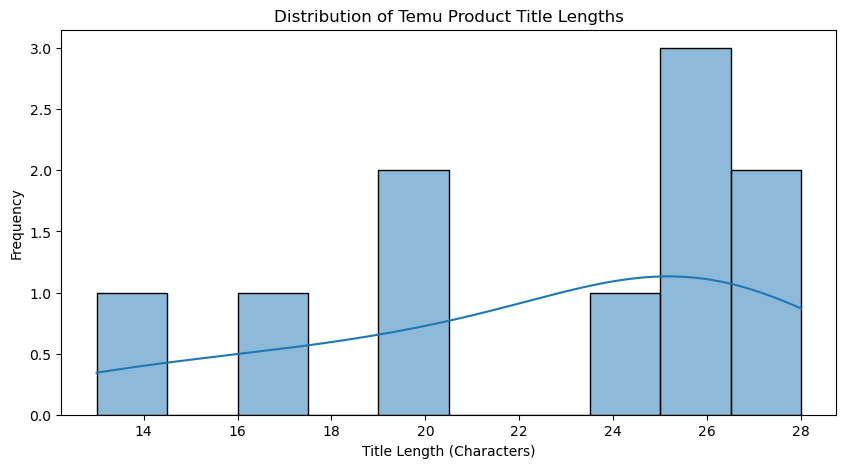

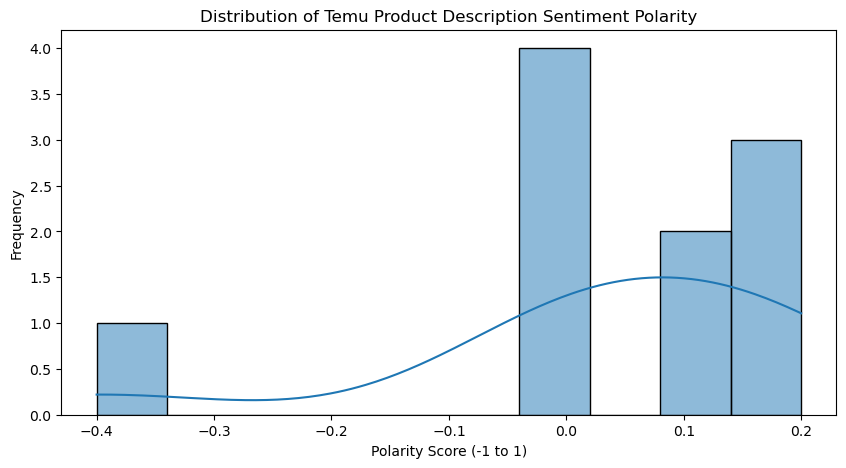

In [24]:
# Exploratory data analysis: distributions

import matplotlib.pyplot as plt
import seaborn as sns

if not df.empty:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        df["title_length"],
        kde=True,
        bins=min(10, max(3, len(df)))
    )

    plt.title("Distribution of Temu Product Title Lengths")
    plt.xlabel("Title Length (Characters)")
    plt.ylabel("Frequency")
    plt.show()


    plt.figure(figsize=(10, 5))

    sns.histplot(
        df["sentiment_polarity"],
        kde=True,
        bins=min(10, max(3, len(df)))
    )

    plt.title(
        "Distribution of Temu Product Description Sentiment Polarity"
    )

    plt.xlabel("Polarity Score (-1 to 1)")
    plt.ylabel("Frequency")
    plt.show()

else:
    print("No data available for plotting.")

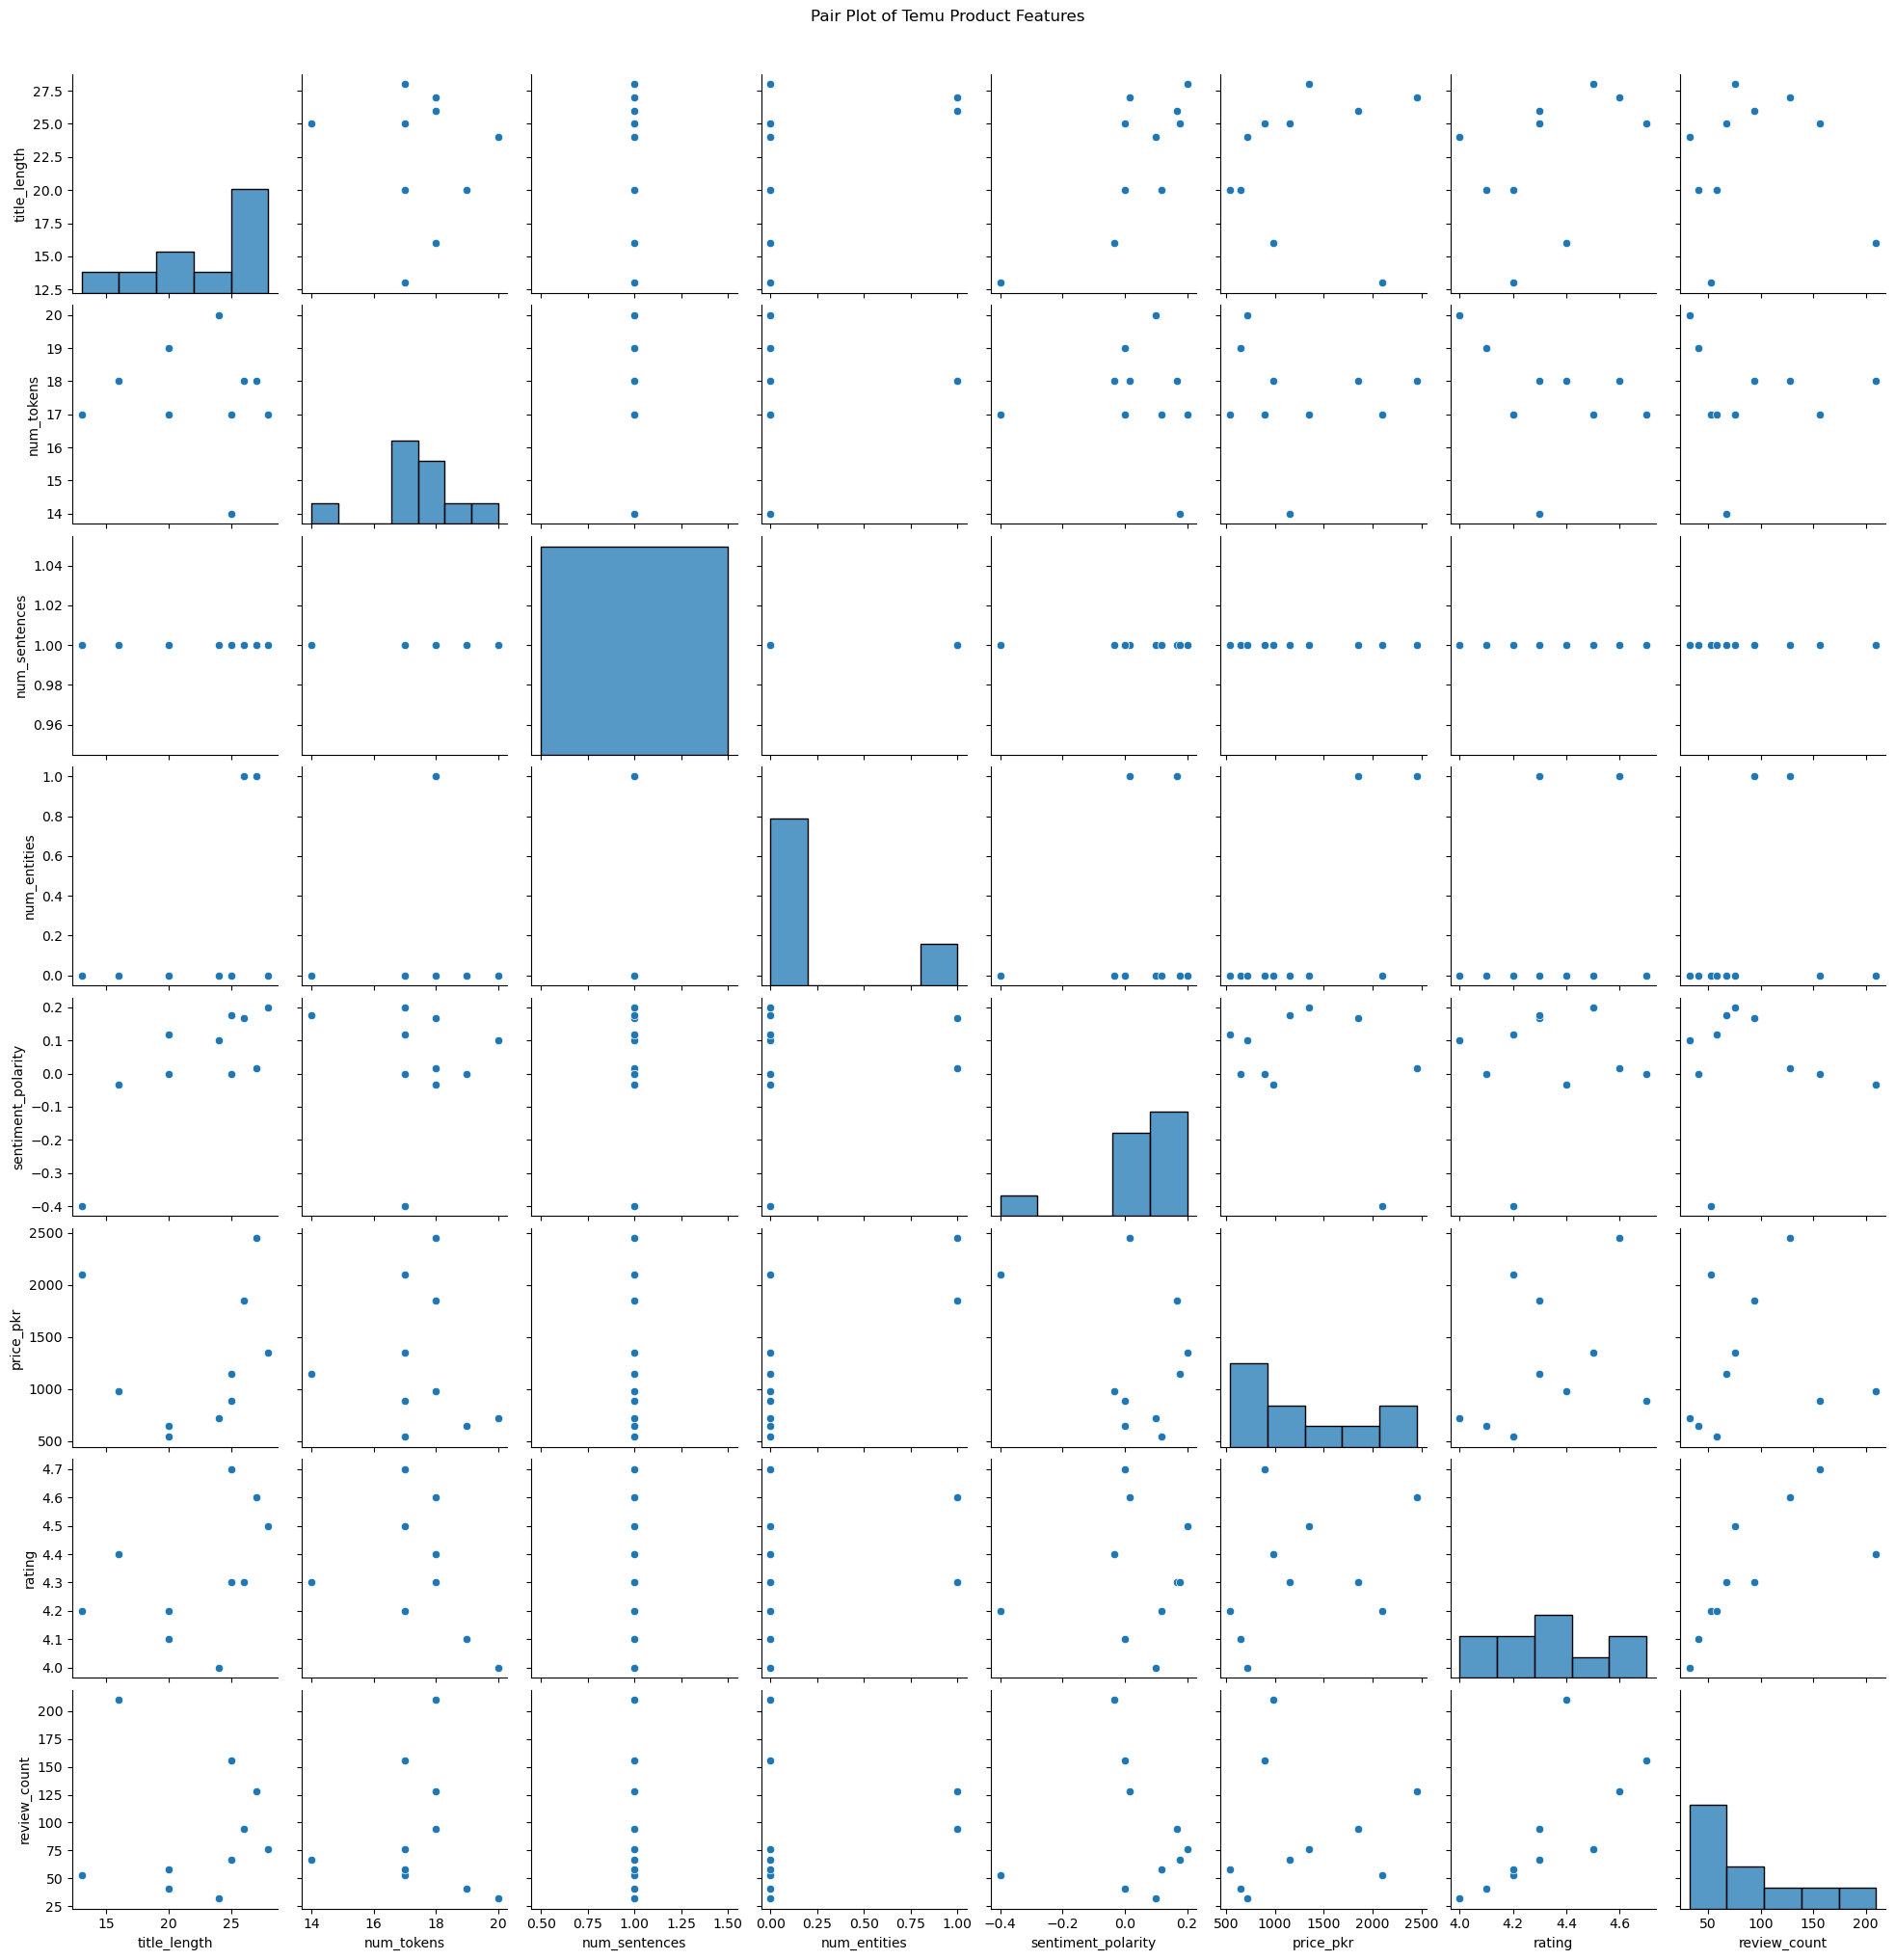

In [25]:
# Pair plot of numeric product features

numeric_cols = [
    col for col in [
        "title_length",
        "num_tokens",
        "num_sentences",
        "num_entities",
        "sentiment_polarity",
        "price_pkr",
        "rating",
        "review_count"
    ]
    if col in df.columns
    and pd.to_numeric(df[col], errors="coerce").notna().any()
]


if len(numeric_cols) >= 2:

    plot_data = (
        df[numeric_cols]
        .apply(pd.to_numeric, errors="coerce")
        .dropna()
    )

    if len(plot_data) >= 2:

        sns.pairplot(plot_data)

        plt.suptitle(
            "Pair Plot of Temu Product Features",
            y=1.02
        )

        plt.show()

    else:
        print("Not enough complete rows for a pair plot.")

else:
    print("Not enough numeric columns for a pair plot.")

Correlation matrix:



,title_length,num_tokens,num_sentences,num_entities,sentiment_polarity,price_pkr,rating,review_count
title_length,1.00,-0.08,NaN,0.43,0.79,0.10,0.41,-0.04
num_tokens,-0.08,1.00,NaN,0.17,-0.10,-0.11,-0.33,-0.06
num_sentences,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_entities,0.43,0.17,NaN,1.00,0.17,0.71,0.29,0.18
sentiment_polarity,0.79,-0.10,NaN,0.17,1.00,-0.34,0.09,-0.05
price_pkr,0.10,-0.11,NaN,0.71,-0.34,1.00,0.36,0.13
rating,0.41,-0.33,NaN,0.29,0.09,0.36,1.00,0.71
review_count,-0.04,-0.06,NaN,0.18,-0.05,0.13,0.71,1.00


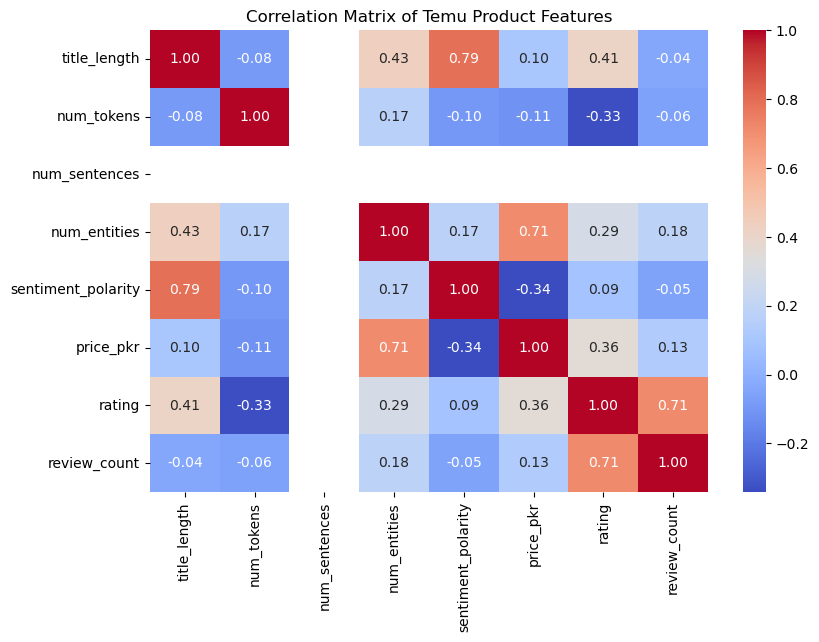

In [26]:
# Correlation matrix

print("Correlation matrix:\n")

if len(numeric_cols) >= 2:

    correlation = (
        df[numeric_cols]
        .apply(pd.to_numeric, errors="coerce")
        .corr()
    )

    display(correlation.round(2))

    plt.figure(figsize=(9, 6))

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Matrix of Temu Product Features")
    plt.show()

else:
    print("Not enough numeric columns for correlation analysis.")

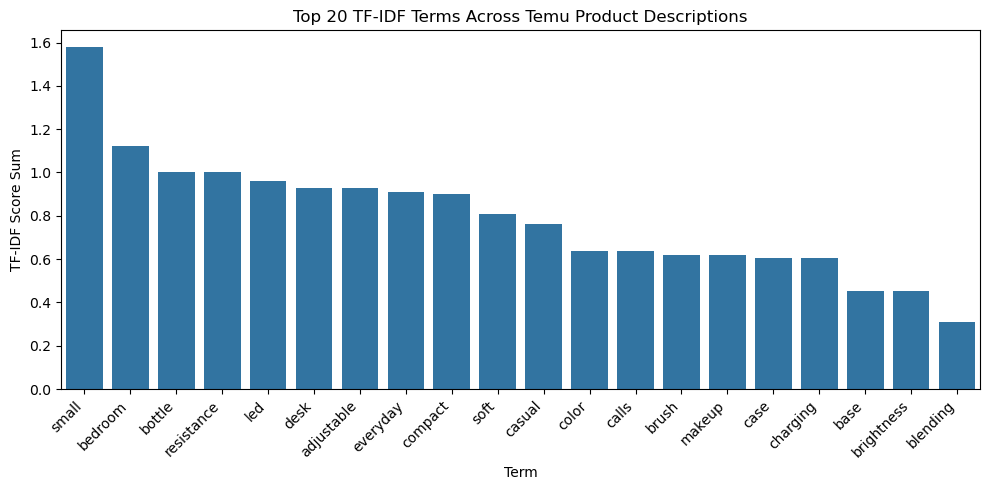

Sparse matrix shape (documents x terms): (10, 20)


In [27]:
# TF-IDF: identify important words in Temu product descriptions

from sklearn.feature_extraction.text import TfidfVectorizer


if not df.empty and df["text"].fillna("").str.strip().ne("").any():

    vectorizer = TfidfVectorizer(
        stop_words="english",
        max_features=20
    )

    X = vectorizer.fit_transform(
        df["text"].fillna("").astype(str)
    )

    tfidf_df = pd.DataFrame(
        X.toarray(),
        columns=vectorizer.get_feature_names_out()
    )

    tfidf_sums = (
        tfidf_df.sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=tfidf_sums.index,
        y=tfidf_sums.values
    )

    plt.title(
        "Top 20 TF-IDF Terms Across Temu Product Descriptions"
    )

    plt.ylabel("TF-IDF Score Sum")
    plt.xlabel("Term")

    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

    print(
        "Sparse matrix shape (documents x terms):",
        X.shape
    )

else:
    print("No product text available for TF-IDF analysis.")